## Installations
---

In [49]:
%%capture

!pip install -q gdown segmentation-models-pytorch albumentations
!pip install -q transformers
!pip install -q optuna

### Import Libraries
---

In [50]:
import os
import json
import random
import zipfile

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp
from transformers import SegformerForSemanticSegmentation, SegformerConfig
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from tqdm import tqdm

import optuna

In [51]:
DEVICE = 'cuda'

DEVICE

'cuda'

## Configurations
---

In [52]:
CFG = {
    "arch" : "segformer",
    "init" : "imagenet",
    "backbone" : "mit_b3",
    "run_version" : "v4",     
    "img_size" : 512,
    "batch_size" : 4,
    "epochs" : 40,
    "patience" : 8,
    "lr_encoder" : 1e-5,
    "lr_decoder" : 3e-4,
    "weight_decay" : 1e-4,
    "seed" : 42,
    "dice_weight" : 0.7,
    "ce_weight" : 0.3,
    "threshold" : 0.5,
    "dup_hamming" : 5,
    "n_trials" : 30,
    "hpo_epochs" : 12,
    "hpo_hours" : 9.5         # Kaggle stops a session at 12 h; no new trial after 9.5 h leaves time for final training
}

In [53]:
CFG['run_id'] = f"{CFG['arch']}-{CFG['backbone']}-{CFG['init']}"
CFG

{'arch': 'segformer',
 'init': 'imagenet',
 'backbone': 'mit_b3',
 'run_version': 'v4',
 'img_size': 512,
 'batch_size': 4,
 'epochs': 40,
 'patience': 8,
 'lr_encoder': 1e-05,
 'lr_decoder': 0.0003,
 'weight_decay': 0.0001,
 'seed': 42,
 'dice_weight': 0.7,
 'ce_weight': 0.3,
 'threshold': 0.5,
 'dup_hamming': 5,
 'n_trials': 30,
 'hpo_epochs': 12,
 'hpo_hours': 9.5,
 'run_id': 'segformer-mit_b3-imagenet'}

- Seeding (Randomness)

In [54]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

In [55]:
set_seed(CFG['seed'])

## Download Dataset
---

In [56]:
file_id = "114xnPVZtthHi4Bejzho33vGJSqb4-F8g"
output_zip = "/tmp/dataset.zip"
extract_path = Path("/tmp/flopwd_data")

In [57]:
!gdown --id {file_id} -O {output_zip}

if os.path.exists(output_zip):
    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(output_zip, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Success! Dataset extracted to {extract_path}")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=114xnPVZtthHi4Bejzho33vGJSqb4-F8g
From (redirected): https://drive.google.com/uc?id=114xnPVZtthHi4Bejzho33vGJSqb4-F8g&confirm=t&uuid=305ef630-32fc-4d04-8818-7731e576386b
To: /tmp/dataset.zip
100%|████████████████████████████████████████| 358M/358M [00:04<00:00, 71.8MB/s]
Success! Dataset extracted to /tmp/flopwd_data


## Import Dataset
---

In [58]:
dataset_path = extract_path / "Dal Lake Floating Plastic Waste Detection Dataset (FloPWD 2025)"
raw_dir = dataset_path / "Raw_Images"
mask_dir = dataset_path / "Segmentation_Masks"
labels_csv = dataset_path / "Image_labels_Binary Classification Task.csv"
reg_csv = dataset_path / "Mask_foreground_percentages_Regression Task.csv"

In [59]:
"images:", len(list(raw_dir.glob("*.jpg")))

('images:', 2002)

In [60]:
"masks :", len(list(mask_dir.glob("*.png")))

('masks :', 2002)

### Build Dataframe

In [61]:
labels_df = pd.read_csv(labels_csv)

labels_df = labels_df.rename(columns={
    "image name" : "image_name",
    "Presence of plastic waste?" : "presence"
})

In [62]:
reg_df = pd.read_csv(reg_csv)

reg_df = reg_df.rename(columns={
    "image name" : "image_name",
    "plastic waste accumulation (in percentage)" : "fg_pct"
})

- merge

In [63]:
df = labels_df.merge(reg_df, on="image_name", how="inner")

df['image_path'] = df['image_name'].apply(lambda x: str(raw_dir / x))
df['mask_path'] = df['image_name'].str.replace('.jpg', "_mask.png", regex=False).apply(lambda x: str(mask_dir / x))
df['has_plastic'] = (df['presence'].astype(str).str.lower() == 'yes').astype(int)
df['fg_pct'] = df['fg_pct'].astype(float)

In [64]:
df.head()

,image_name,presence,fg_pct,image_path,mask_path,has_plastic
0,img1.jpg,yes,0.08,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,1
1,img2.jpg,yes,0.03,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,1
2,img3.jpg,yes,0.38,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,1
3,img4.jpg,yes,0.20,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,1
4,img5.jpg,yes,0.18,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,/tmp/flopwd_data/Dal Lake Floating Plastic Was...,1


### EDA
---

In [65]:
r = df.iloc[0]
img = cv2.cvtColor(cv2.imread(r['image_path']), cv2.COLOR_BGR2RGB)
mask = (cv2.imread(r['mask_path'], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)

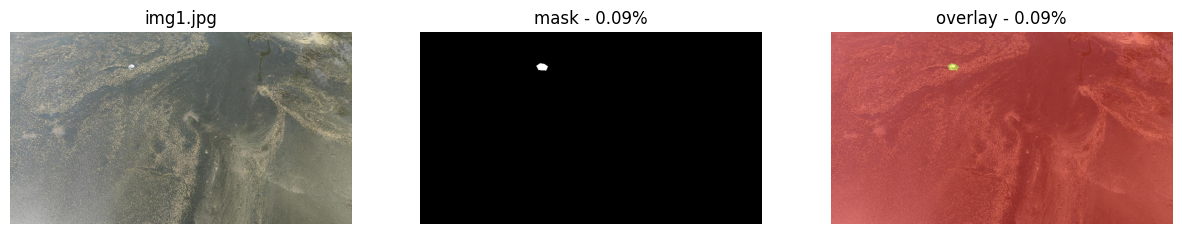

In [66]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].imshow(img)
ax[0].set_title(r['image_name'])

ax[1].imshow(mask, cmap='gray')
ax[1].set_title(f'mask - {mask.mean()*100:.2f}%')

ax[2].imshow(img)
ax[2].imshow(mask, alpha=0.4, cmap='autumn')
ax[2].set_title(f'overlay - {mask.mean()*100:.2f}%')

for a in ax:
    a.axis('off')

## Split
---

In [67]:
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=CFG['seed'], stratify=df['has_plastic'])

In [68]:
train_df, val_df = train_test_split(train_val_df, test_size=15/85, random_state=CFG['seed'], stratify=train_val_df['has_plastic'])

In [69]:
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

In [70]:
len(train_df), len(val_df), len(test_df)

(1400, 301, 301)

## Image Augmentation
---

In [71]:
S = CFG['img_size']
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

In [72]:
train_tf = A.Compose([
    A.Resize(S, S),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [73]:
eval_tf = A.Compose([
    A.Resize(S, S),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2()
])

## Training - Dataset
---

In [74]:
class FloPWD(Dataset):

    def __init__(self, frame, tf):
        self.df, self.tf = frame, tf

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = cv2.cvtColor(cv2.imread(r['image_path']), cv2.COLOR_BGR2RGB)
        mask = (cv2.imread(r['mask_path'], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
        out = self.tf(image=img, mask=mask)
        return out['image'], out['mask'].long()

## Training - DataLoader
---

In [75]:
B = CFG['batch_size']

In [76]:
train_loader = DataLoader(FloPWD(train_df, train_tf), batch_size=B, shuffle=True, num_workers=4, persistent_workers=True, pin_memory=True, drop_last=True)
val_loader = DataLoader(FloPWD(val_df, eval_tf), batch_size=B, shuffle=False, num_workers=4, persistent_workers=True, pin_memory=True)
test_loader = DataLoader(FloPWD(test_df, eval_tf), batch_size=B, shuffle=False, num_workers=4, pin_memory=True)

## Model
---

In [77]:
ARCH = {
    "unet" : smp.Unet,
    "deeplab" : smp.DeepLabV3Plus,
    "unetpp" : smp.UnetPlusPlus,
    "upernet" : smp.UPerNet
}

In [78]:
def build_model(arch, init, backbone):
    if arch in ARCH:

        model = ARCH[arch](
            encoder_name = backbone,
            encoder_weights = "imagenet" if init == "imagenet" else None,
            classes = 2
        )

        if init == "aerial":
            from torchgeo.models import ResNet50_Weights
            sd = ResNet50_Weights.FMOW_RGB_GASSL.get_state_dict(progress=True)
            missing, unexpected = model.encoder.load_state_dict(sd, strict=False)

        return model

    hf = "nvidia/" + backbone.replace("_", "-")

    src = {
        "raw" : None,
        "imagenet" : hf,
        "aerial" : "restor/tcd-segformer-mit-b3",               
        "ade" : "nvidia/segformer-b3-finetuned-ade-512-512",    
        "drone" : "pablojrios/segformer-b3-finetuned-drones"
    }[init]

    if src is None:
        cfg = SegformerConfig.from_pretrained(hf, num_labels=2)
        return SegformerForSemanticSegmentation(cfg)

    return SegformerForSemanticSegmentation.from_pretrained(src, num_labels=2, ignore_mismatched_sizes=True)

## Loss
---

In [79]:
sub = train_df.sample(
    min(200, len(train_df)),
    random_state=CFG['seed']
)

pos = 0
neg = 0

In [80]:
for _, r in sub.iterrows():
    mask = cv2.imread(r["mask_path"], cv2.IMREAD_GRAYSCALE) > 127
    pos += int(mask.sum())
    neg += int(mask.size - mask.sum())

In [81]:
pos_weight = neg / max(pos, 1)

pos_weight

18.368890673898054

### Dice Loss
---

In [82]:
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.softmax(logits, dim=1)[:, 1]
    t = targets.float()
    inter = (probs * t).sum(dim=(1, 2))
    union = probs.sum(dim=(1, 2)) + t.sum(dim=(1, 2))
    return 1.0 - ((2 * inter + smooth) / (union + smooth)).mean()

### Criterion
---

In [83]:
w  = torch.tensor([1.0, float(min(pos_weight, 50.0))], device=DEVICE)
ce = nn.CrossEntropyLoss(weight=w)

In [84]:
def criterion(logits, targets):
    return CFG["dice_weight"] * dice_loss(logits, targets) + CFG["ce_weight"] * ce(logits, targets)

## Optimizer
---

In [85]:
def build_optimizer(model):
    if CFG['arch'] == 'segformer':
        enc = list(model.segformer.parameters())
        dec = list(model.decode_head.parameters())
    else:
        enc = list(model.encoder.parameters())
        dec = [q for n, q in model.named_parameters() if not n.startswith('encoder.')]

    lr_enc = CFG["lr_decoder"] if CFG["init"] == "raw" else CFG["lr_encoder"]

    return torch.optim.AdamW(
        [{"params": enc, "lr": lr_enc}, {"params": dec, "lr": CFG["lr_decoder"]}],
        weight_decay=CFG["weight_decay"]
    )

## Training
---

### Forward Pass

In [86]:
def forward_logits(model, x):
    out = model(x)

    if hasattr(out, "logits"):
        return F.interpolate(out.logits, size=x.shape[-2:], mode='bilinear', align_corners=False)

    return out

### Metrics

In [87]:
def compute_stats(tp, fp, fn, tn, eps=1e-7):
    fg = tp / (tp + fp + fn + eps)
    bg = tn / (tn + fp + fn + eps)
    recall = tp / (tp + fn + eps)   # = foreground pixel accuracy
    bg_acc = tn / (tn + fp + eps)   # background pixel accuracy

    return {"foreground_iou": fg, "background_iou": bg, "miou": (fg + bg) / 2,
            "dice": 2*tp / (2*tp + fp + fn + eps),
            "precision": tp / (tp + fp + eps),
            "recall": recall,
            "background_acc": bg_acc,
            "mpa": (recall + bg_acc) / 2   # mean pixel accuracy; plain pixel accuracy would be ~95% for an all-background guess
    }

### Epoch

In [88]:
def train_epoch():
    model.train()

    total = 0.0
    for x, y in tqdm(train_loader, desc='train', leave=False):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        with torch.amp.autocast("cuda", enabled=(DEVICE == "cuda")):
            loss = criterion(forward_logits(model, x), y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total += loss.item()

    return total / len(train_loader)

In [89]:
@torch.no_grad()
def evaluate(loader):
    model.eval()

    c = torch.zeros(4, dtype=torch.float64, device=DEVICE)
    total = 0.0
    for x, y in tqdm(loader, desc="eval", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)

        with torch.amp.autocast("cuda", enabled=(DEVICE == "cuda")):
            logits = forward_logits(model, x).float()

        total += criterion(logits, y).item()

        p = (torch.softmax(logits, dim=1)[:, 1] > CFG["threshold"]).float()
        t = y.float()

        c += torch.stack([(p * t).sum(), (p * (1 - t)).sum(), ((1 - p) * t).sum(), ((1 - p) * (1 - t)).sum()]).double()

    res = {k: float(v) for k, v in compute_stats(*c).items()}

    res["loss"] = total / len(loader)

    return res

## Hyperparameter Tuning
---

In [90]:
OUT = Path(f"/kaggle/working/runs/{CFG['run_id']}/{CFG['run_version']}")
OUT.mkdir(parents=True, exist_ok=True)
best_path = OUT / "best.pth"

In [91]:
import shutil

# ponytail: resume an old study by attaching its optuna.db as a Kaggle Dataset; does nothing if none is attached
prev = next(Path("/kaggle/input").rglob("optuna.db"), None)

if prev and not (OUT / "optuna.db").exists():
    shutil.copy(prev, OUT / "optuna.db")

prev

### Search Space

In [92]:
def suggest(trial):
    dice = trial.suggest_float("dice_weight", 0.3, 0.9)

    return {
        "lr_encoder" : trial.suggest_float("lr_encoder", 1e-6, 1e-4, log=True),
        "lr_decoder" : trial.suggest_float("lr_decoder", 3e-5, 3e-3, log=True),
        "weight_decay" : trial.suggest_float("weight_decay", 1e-5, 5e-2, log=True),
        "dice_weight" : dice,
        "ce_weight" : 1 - dice
    }

### Objective

In [93]:
def objective(trial):
    global model, optimizer, scaler

    CFG.update(suggest(trial))
    set_seed(CFG['seed'])

    model = build_model(CFG['arch'], CFG['init'], CFG['backbone']).to(DEVICE)
    optimizer = build_optimizer(model)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
    scheduler = torch.optim.lr_scheduler.PolynomialLR(optimizer, total_iters=CFG["hpo_epochs"], power=1.0)

    hist = []
    for ep in range(1, CFG["hpo_epochs"] + 1):
        train_epoch()
        scheduler.step()
        hist.append(evaluate(val_loader)["miou"])
        score = float(np.mean(hist[-3:]))

        trial.report(score, ep)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return score

### Study

In [94]:
study = optuna.create_study(
    study_name = CFG['run_id'],
    storage = f"sqlite:///{OUT / 'optuna.db'}",
    load_if_exists = True,
    direction = "maximize",
    sampler = optuna.samplers.TPESampler(seed=CFG['seed']),
    pruner = optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=5)
)

[I 2026-10-23 14:23:02,569] Using an existing study with `study_name='segformer-mit_b3-imagenet'` instead of creating a new one.


In [95]:
if len(study.trials) == 0:
    study.enqueue_trial({k: CFG[k] for k in ["lr_encoder", "lr_decoder", "weight_decay", "dice_weight"]})

In [96]:
done = len(study.get_trials(states=(optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)))

study.optimize(objective, n_trials=max(0, CFG["n_trials"] - done), timeout=CFG["hpo_hours"] * 3600)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/628 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_fuse.weight                          

Loading weights:   0%|          | 0/628 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_fuse.weight                          

...

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_fuse.weight                          

Loading weights:   0%|          | 0/628 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_fuse.weight                          

Loading weights:   0%|          | 0/628 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_fuse.weight                          

### Trials

In [97]:
trials = study.trials_dataframe()
trials.to_csv(OUT / "trials.csv", index=False)

trials.sort_values("value", ascending=False).head(10)

,number,value,datetime_start,datetime_complete,duration,params_dice_weight,params_lr_decoder,params_lr_encoder,params_weight_decay,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
15,15,0.813553,2026-10-23 20:05:13.013137,2026-10-23 20:31:15.869474,0 days 00:26:02.856337,0.756356,0.000034,0.000027,0.001645,NaN,"{""dice_weight"": 0.7563564386769535, ""lr_decode...",COMPLETE
16,16,0.811874,2026-10-23 20:31:15.890399,2026-10-23 20:57:18.088958,0 days 00:26:02.198559,0.734884,0.000053,0.000074,0.000243,NaN,"{""dice_weight"": 0.734884074385295, ""lr_decoder...",COMPLETE
19,19,0.811680,2026-10-23 21:49:17.604643,2026-10-23 22:15:17.358485,0 days 00:25:59.753842,0.784937,0.000032,0.000099,0.000302,NaN,"{""dice_weight"": 0.7849368872814664, ""lr_decode...",COMPLETE
17,17,0.810552,2026-10-23 20:57:18.107973,2026-10-23 21:23:19.577376,0 days 00:26:01.469403,0.764626,0.000043,0.000038,0.001754,NaN,"{""dice_weight"": 0.7646261282756687, ""lr_decode...",COMPLETE
12,12,0.809241,2026-10-23 19:02:14.735290,2026-10-23 19:28:17.985019,0 days 00:26:03.249729,0.713486,0.000051,0.000029,0.029263,NaN,"{""dice_weight"": 0.7134864216810748, ""lr_decode...",COMPLETE
18,18,0.808757,2026-10-23 21:23:19.594779,2026-10-23 21:49:17.580651,0 days 00:25:57.985872,0.775182,0.000103,0.000093,0.000825,NaN,"{""dice_weight"": 0.7751821954899851, ""lr_decode...",COMPLETE
21,21,0.807518,2026-10-23 22:41:20.557113,2026-10-23 23:07:22.308280,0 days 00:26:01.751167,0.843040,0.000046,0.000014,0.000631,NaN,"{""dice_weight"": 0.8430403617535686, ""lr_decode...",COMPLETE
3,3,0.806774,2026-10-23 15:14:43.535844,2026-10-23 15:40:46.731950,0 days 00:26:03.196106,0.660669,0.000033,0.000026,0.038696,NaN,NaN,COMPLETE
13,13,0.805292,2026-10-23 19:28:18.006016,2026-10-23 19:54:20.220557,0 days 00:26:02.214541,0.705255,0.000072,0.000040,0.016354,NaN,"{""dice_weight"": 0.7052549970217783, ""lr_decode...",COMPLETE
20,20,0.804533,2026-10-23 22:15:17.375976,2026-10-23 22:41:20.539745,0 days 00:26:03.163769,0.569166,0.000048,0.000081,0.000129,NaN,"{""dice_weight"": 0.5691660078288459, ""lr_decode...",COMPLETE


In [98]:
study.best_trial.number, study.best_value, study.best_params

(15,
 0.8135528537644667,
 {'dice_weight': 0.7563564386769535,
  'lr_encoder': 2.6794041619173922e-05,
  'lr_decoder': 3.3834056423814834e-05,
  'weight_decay': 0.0016453302993209963})

### Plots

In [99]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances, plot_slice

/tmp/ipykernel_48/1011915927.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


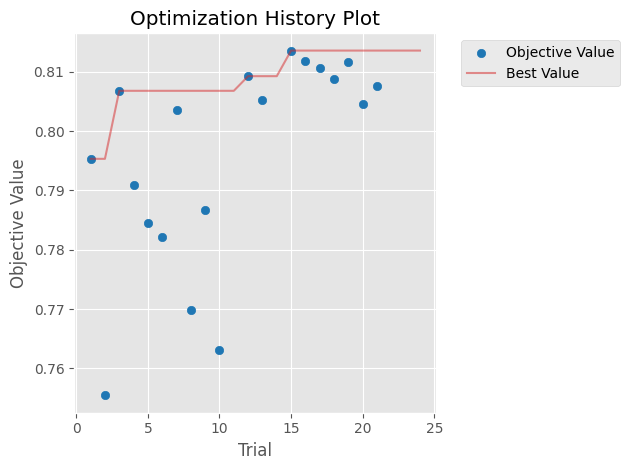

In [100]:
plot_optimization_history(study)
plt.savefig(OUT / "hpo_history.png", dpi=110, bbox_inches="tight")

/tmp/ipykernel_48/295749319.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


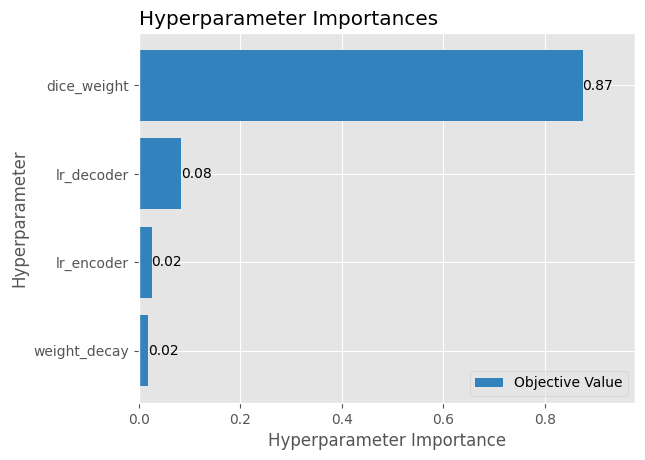

In [101]:
plot_param_importances(study)
plt.savefig(OUT / "hpo_importance.png", dpi=110, bbox_inches="tight")

/tmp/ipykernel_48/3679895991.py:1: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  plot_slice(study)


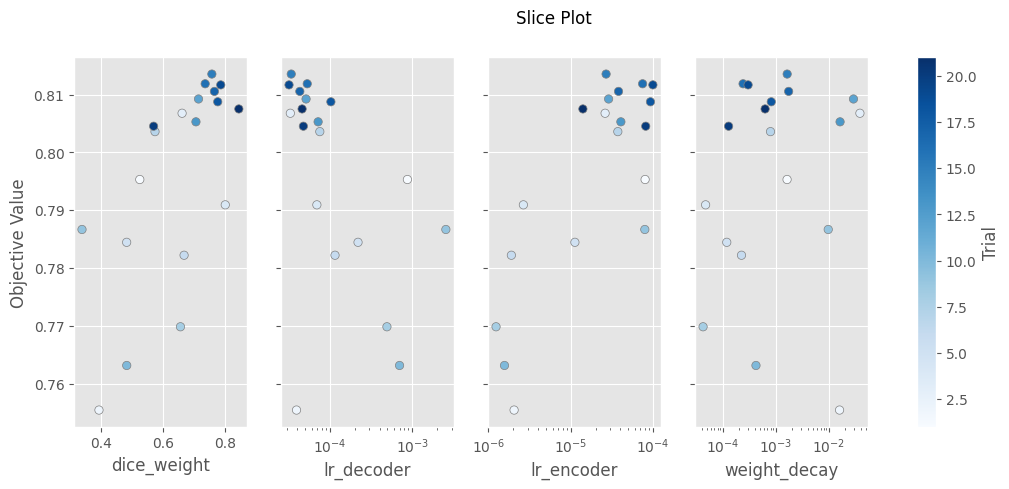

In [102]:
plot_slice(study)
plt.savefig(OUT / "hpo_slice.png", dpi=110, bbox_inches="tight")

## Final Training
---

In [103]:
CFG.update(study.best_params)
CFG["ce_weight"] = 1 - CFG["dice_weight"]
set_seed(CFG['seed'])

In [104]:
model = build_model(CFG['arch'], CFG['init'], CFG['backbone']).to(DEVICE)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/628 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b3
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.bias                                         | UNEXPECTED | 
classifier.weight                                       | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_fuse.weight                          

### Weight Fingerprint
---

In [105]:
p = next(model.parameters())

In [106]:
f"{CFG['run_id']:24s} mean={float(p.mean()):+.6f}  std={float(p.std()):.6f}"

/tmp/ipykernel_48/2017929731.py:1: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  f"{CFG['run_id']:24s} mean={float(p.mean()):+.6f}  std={float(p.std()):.6f}"


'segformer-mit_b3-imagenet mean=-0.000003  std=0.054351'

In [107]:
"parameters:", round(sum(q.numel() for q in model.parameters()) / 1e6, 2), "M"

('parameters:', 47.22, 'M')

In [108]:
optimizer = build_optimizer(model)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
scheduler = torch.optim.lr_scheduler.PolynomialLR(optimizer, total_iters=CFG["epochs"], power=1.0)

### Main Loop

In [109]:
best, bad, history = -1.0, 0, []

for ep in range(1, CFG["epochs"] + 1):
    tr = train_epoch()
    scheduler.step()

    va = evaluate(val_loader)

    history.append({"epoch": ep, "train_loss": tr, **{f"val_{k}": v for k, v in va.items()}})
    pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)

    if va["miou"] > best:
        best, bad = va["miou"], 0
        torch.save(model.state_dict(), best_path)
        print(f"saved (mIoU {best:.4f})")
    else:
        bad += 1
        if bad >= CFG["patience"]:
            print(f"early stop at epoch {ep}")
            break

saved (mIoU 0.7686)


saved (mIoU 0.7887)


saved (mIoU 0.7936)


saved (mIoU 0.8096)


early stop at epoch 16


In [110]:
train_df[["image_name"]].assign(split="train").to_csv(OUT / "split_train.csv", index=False)
val_df[["image_name"]].assign(split="val").to_csv(OUT / "split_val.csv", index=False)
test_df[["image_name"]].assign(split="test").to_csv(OUT / "split_test.csv", index=False)

## Results
---

In [111]:
model.load_state_dict(torch.load(best_path, map_location=DEVICE))


<All keys matched successfully>

### Training Curves

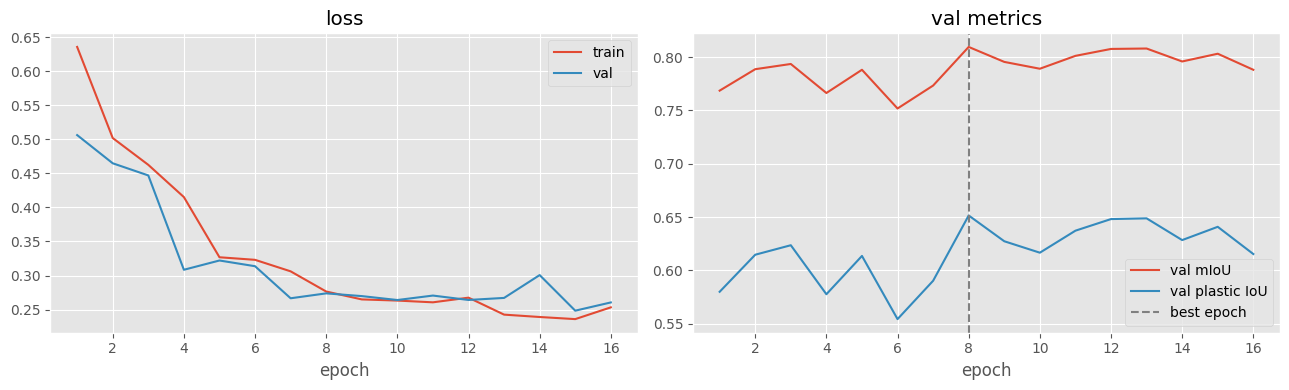

In [112]:
h = pd.read_csv(OUT / "history.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(h["epoch"], h["train_loss"], label="train")
ax[0].plot(h["epoch"], h["val_loss"], label="val")
ax[0].set_title("loss")

ax[1].plot(h["epoch"], h["val_miou"], label="val mIoU")
ax[1].plot(h["epoch"], h["val_foreground_iou"], label="val plastic IoU")
ax[1].axvline(h.loc[h["val_miou"].idxmax(), "epoch"], color="gray", linestyle="--", label="best epoch")
ax[1].set_title("val metrics")

for a in ax:
    a.set_xlabel("epoch")
    a.legend()

plt.tight_layout()
plt.savefig(OUT / "curves.png", dpi=110)

### Threshold (picked on val)

In [113]:
scores = {}
for th in np.arange(0.30, 0.95, 0.05).round(2):
    CFG["threshold"] = float(th)
    scores[float(th)] = evaluate(val_loader)["miou"]

CFG["threshold"] = max(scores, key=scores.get)

CFG["threshold"], scores[CFG["threshold"]]

(0.9, 0.8351742166145348)

In [114]:
res = evaluate(test_loader)

In [115]:
res.update({"run_id": CFG["run_id"], "version": CFG["run_version"],
            "best_val_miou": best, "n_train": len(train_df),
            "n_val": len(val_df), "n_test": len(test_df), "cfg": CFG})

In [116]:
with open(OUT / "test_metrics.json", "w") as f:
    json.dump(res, f, indent=2)

print(json.dumps({k: round(v, 4) for k, v in res.items() if isinstance(v, float)}, indent=2))

{
  "foreground_iou": 0.6477,
  "background_iou": 0.9755,
  "miou": 0.8116,
  "dice": 0.7862,
  "precision": 0.7695,
  "recall": 0.8036,
  "background_acc": 0.9863,
  "mpa": 0.895,
  "loss": 0.2915,
  "best_val_miou": 0.8096
}


### Training Curves

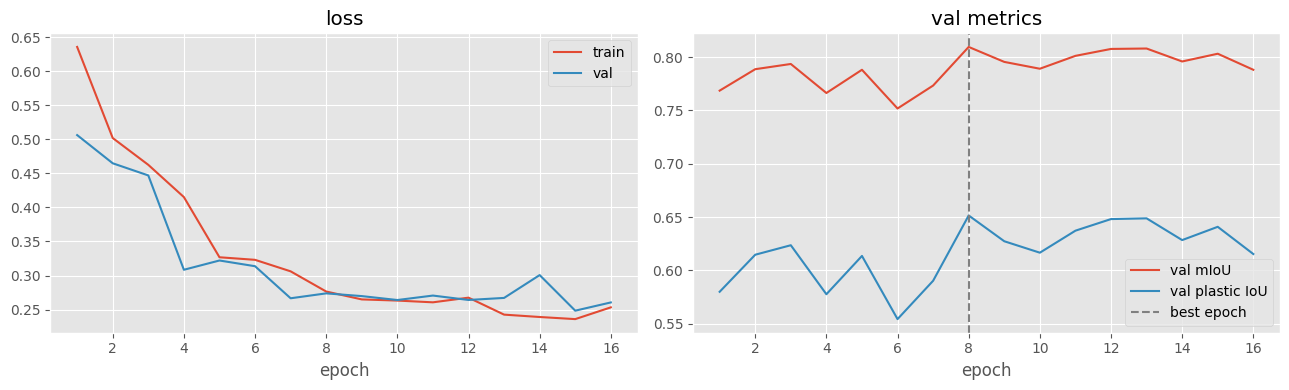

In [117]:
h = pd.read_csv(OUT / "history.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(h["epoch"], h["train_loss"], label="train")
ax[0].plot(h["epoch"], h["val_loss"], label="val")
ax[0].set_title("loss")

ax[1].plot(h["epoch"], h["val_miou"], label="val mIoU")
ax[1].plot(h["epoch"], h["val_foreground_iou"], label="val plastic IoU")
ax[1].axvline(h.loc[h["val_miou"].idxmax(), "epoch"], color="gray", linestyle="--", label="best epoch")
ax[1].set_title("val metrics")

for a in ax:
    a.set_xlabel("epoch")
    a.legend()

plt.tight_layout()
plt.savefig(OUT / "curves.png", dpi=110)

### Samples

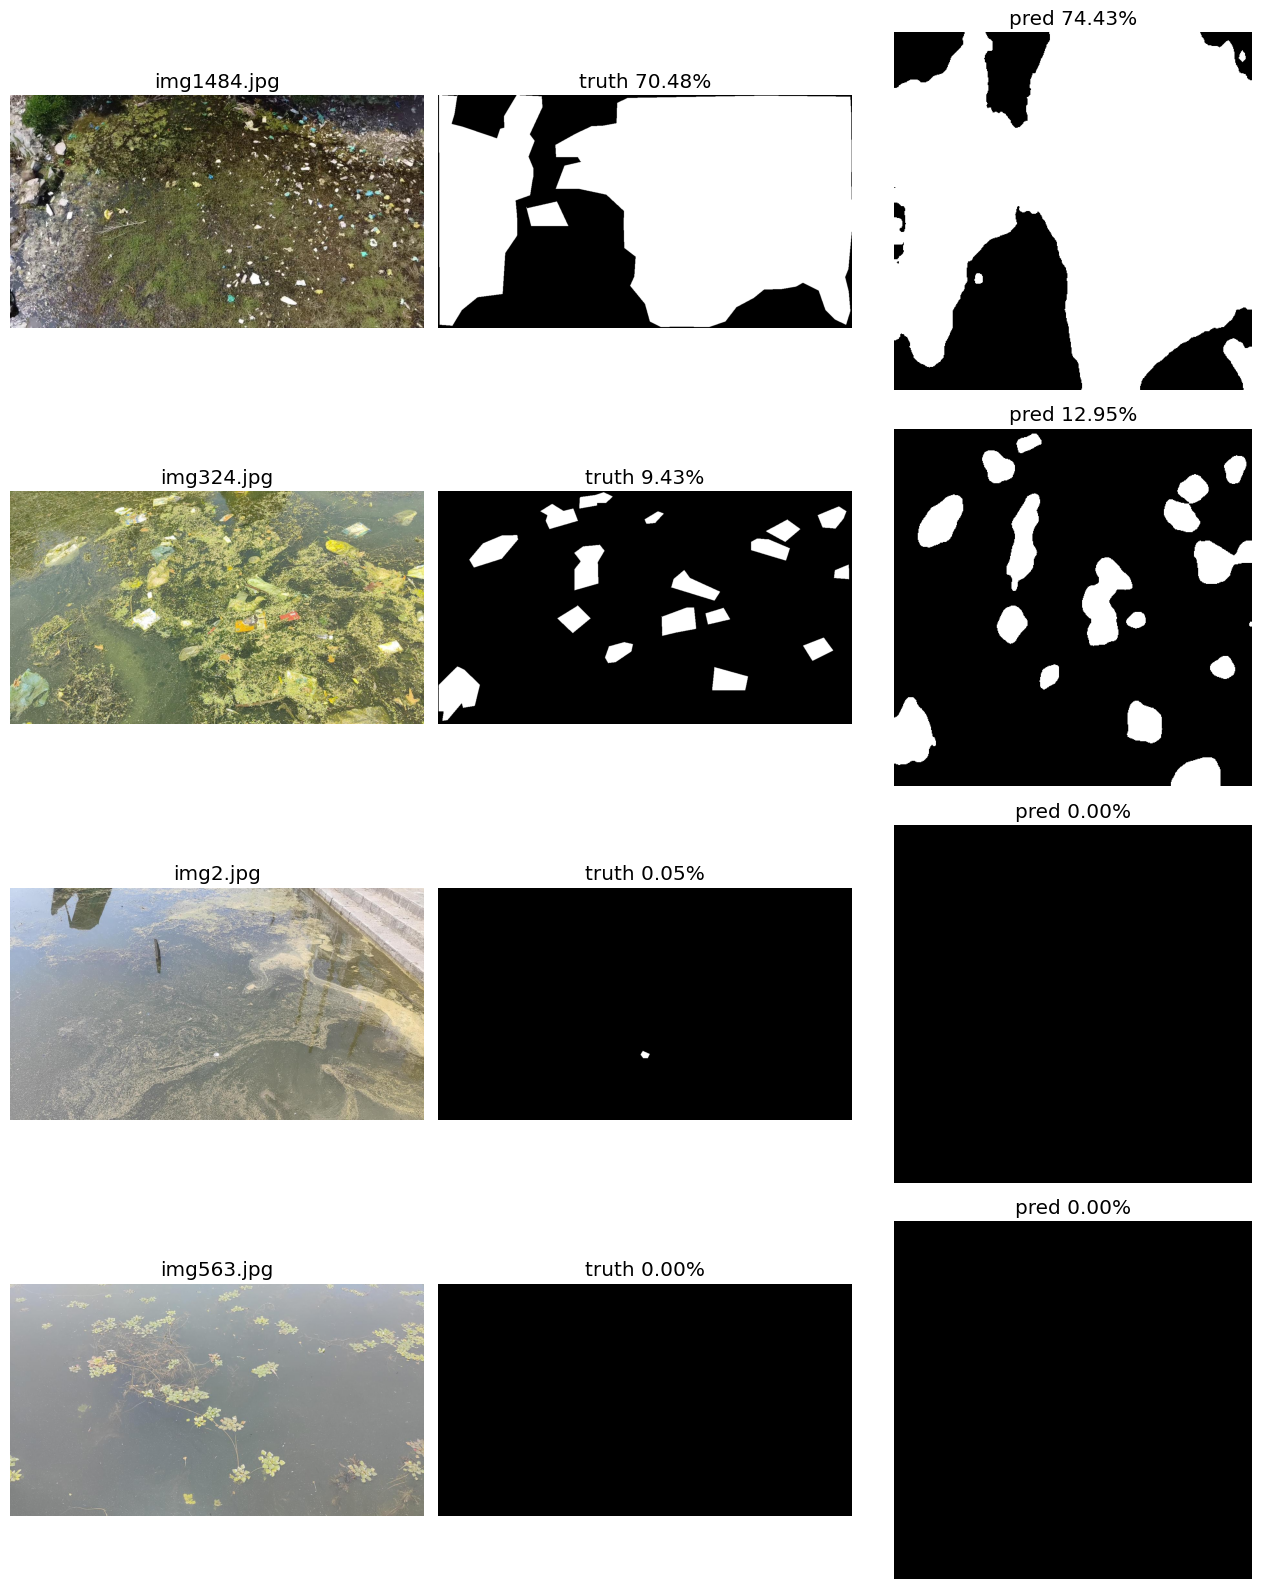

In [118]:
SAMPLES = ["img1484.jpg", "img324.jpg", "img2.jpg", "img563.jpg"]
rows = [df[df.image_name == n].iloc[0] for n in SAMPLES]

fig, ax = plt.subplots(len(rows), 3, figsize=(13, 4 * len(rows)))

for i, r in enumerate(rows):
    img = cv2.cvtColor(cv2.imread(r["image_path"]), cv2.COLOR_BGR2RGB)

    gt  = (cv2.imread(r["mask_path"], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)

    x   = eval_tf(image=img, mask=gt)["image"][None].to(DEVICE)

    with torch.no_grad():
        pr = (torch.softmax(forward_logits(model, x), 1)[0, 1] > CFG["threshold"]).cpu().numpy()

    ax[i,0].imshow(img)
    ax[i,0].set_title(r["image_name"])
    ax[i,1].imshow(gt, cmap="gray")
    ax[i,1].set_title(f"truth {gt.mean()*100:.2f}%")
    ax[i,2].imshow(pr, cmap="gray")
    ax[i,2].set_title(f"pred {pr.mean()*100:.2f}%")

    for a in ax[i]:
        a.axis("off")

plt.tight_layout()
plt.savefig(OUT / "samples.png", dpi=110)

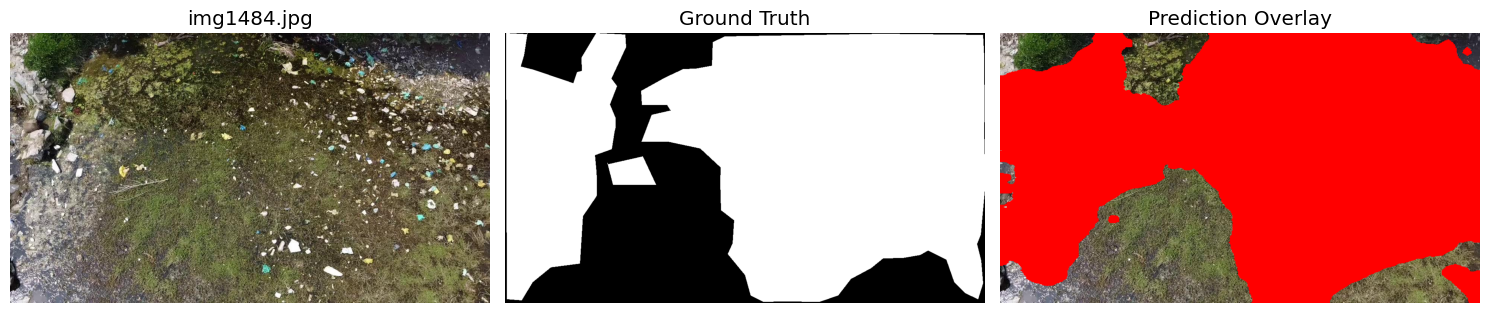

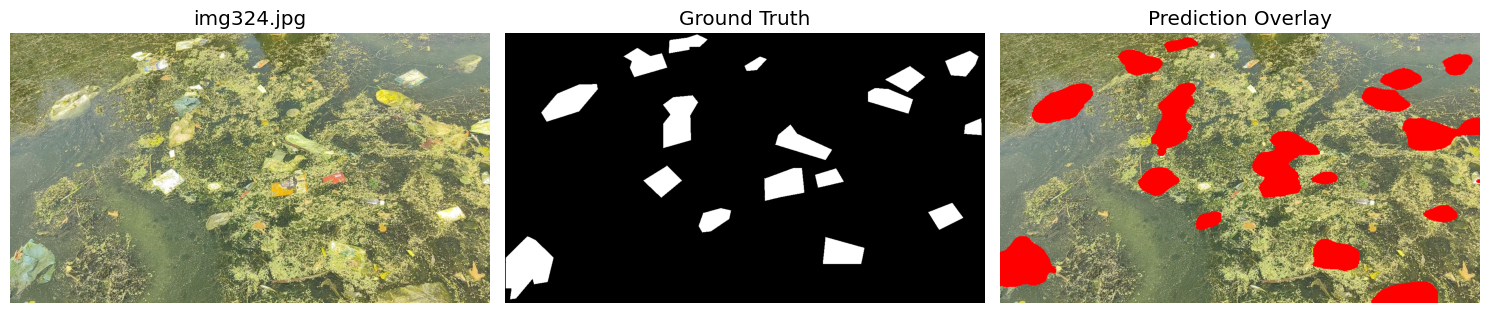

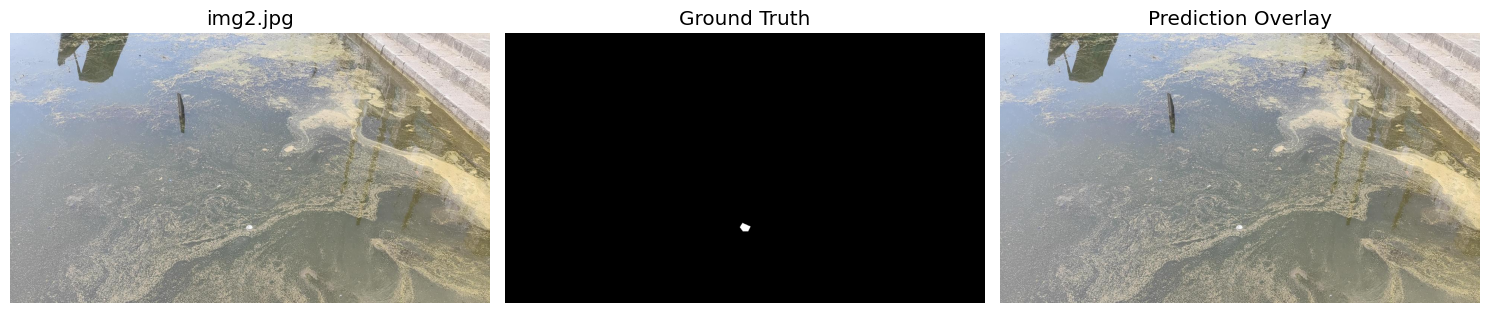

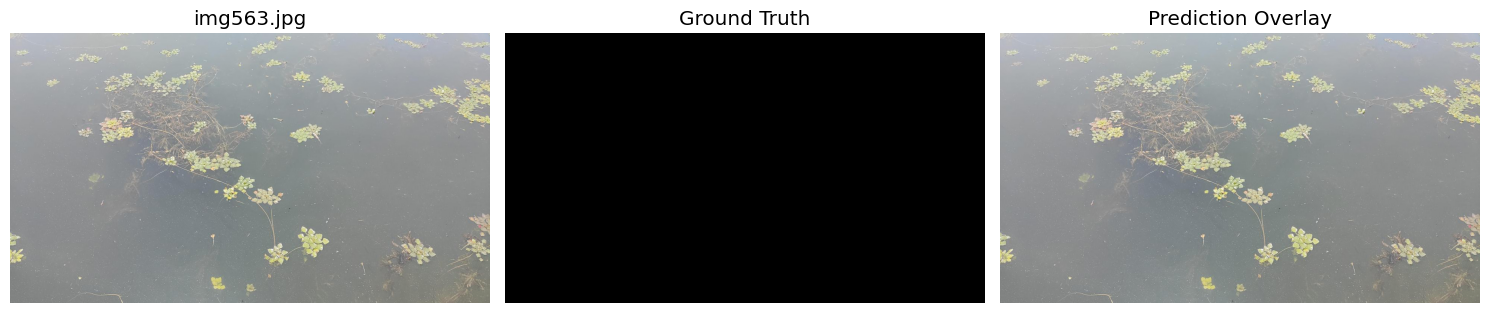

In [119]:
for i, r in enumerate(rows):
    img = cv2.cvtColor(cv2.imread(r["image_path"]), cv2.COLOR_BGR2RGB)
    gt  = (cv2.imread(r["mask_path"], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    x   = eval_tf(image=img, mask=gt)["image"][None].to(DEVICE)

    with torch.no_grad():
        pr = (torch.softmax(forward_logits(model, x), 1)[0, 1] > CFG["threshold"]).cpu().numpy()

    pr_resized = cv2.resize(pr.astype(np.uint8), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    overlay = img.copy()
    overlay[pr_resized == 1] = [255, 0, 0]

    fig, axs = plt.subplots(1, 3, figsize=(15, 5))
    axs[0].imshow(img)
    axs[0].set_title(r["image_name"])
    axs[1].imshow(gt, cmap="gray")
    axs[1].set_title("Ground Truth")
    axs[2].imshow(overlay)
    axs[2].set_title("Prediction Overlay")
    for a in axs:
        a.axis("off")
    plt.tight_layout()
    plt.show()
